# 05. Машинне навчання: Прогнозування стартів у [T, T+1h) та трьохрівневий Ablation Study (A vs B vs C)

Цей блокнот підсумовує результати Етапу 2 на оновленому Feature Store (`797,428` спокійних людино-годин, `is_active_T == 0`, `0` дублікатів):
- **Набір A (10 ознак):** часові цикли, `burden_last_6h`, `burden_last_24h` та Train-only кластери (`low_activity`, `medium_activity`, `high_activity`).
- **Набір B (13 ознак):** A + миттєвий стан сусідів о $T$ (`neighbors_active_count`, `neighbor_any_active`, `neighbor_active_ratio`).
- **Набір C (22 ознаки):** B + адаптивні частоти (`adaptive_rate_7d/14d/30d`), `national_active_count`, `onsets_last_24h` (Варіант А), `hours_since_last_alert` та лаги сусідів за 1, 2, 3 год (`neighbors_active_lag_1h/2h/3h`).
- **Заздалегідь зафіксоване головне порівняння:** `LightGBM (Set C)` проти `Adaptive 14-day Rolling` за парним Day-Block Bootstrap ($N=500$).

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from pathlib import Path

reports_dir = Path("../reports")
val_df = pd.read_csv(reports_dir / "ml_validation_benchmark.csv")
test_df = pd.read_csv(reports_dir / "ml_models_benchmark.csv")
rec_df = pd.read_csv(reports_dir / "ml_recent_60d_benchmark.csv")
imp_df = pd.read_csv(reports_dir / "feature_importance_lightgbm.csv")
details = json.loads((reports_dir / "test_evaluation_details.json").read_text(encoding="utf-8"))

## 1. Результати на Validation (2024-05 — 2025-05, підбір порогів $p^*$)

In [2]:
display(val_df)

,model,feature_set,threshold,precision,recall,f2_score,pr_auc,brier_score
0,Baseline 1: True Naive Persistence,NaN,0.500000,0.230757,0.075949,0.087718,NaN,0.119719
1,Baseline 2: Historical Lookup Table,NaN,0.085235,0.194216,0.749250,0.476754,0.194529,0.086577
2,Baseline 3: Adaptive 14-day Rolling,NaN,0.089195,0.200804,0.761400,0.488594,0.250806,0.083686
3,LogReg (Set A: No Spatial),"A (Time, Burden & Cluster)",0.517586,0.190696,0.778461,0.481590,0.266656,0.235025
4,LogReg (Set B: With Spatial),B (A + Spatial at T),0.561207,0.212022,0.771223,0.504894,0.288191,0.245719
5,LogReg (Set C: Spatial + Adaptive),C (B + Adaptive & Lags),0.565172,0.212014,0.823131,0.522130,0.270086,0.252085
6,LightGBM (Set A: No Spatial),"A (Time, Burden & Cluster)",0.093276,0.206074,0.740926,0.487744,0.268010,0.082417
7,LightGBM (Set B: With Spatial),B (A + Spatial at T),0.109138,0.215688,0.815583,0.524065,0.296142,0.079958
8,LightGBM (Set C: Spatial + Adaptive),C (B + Adaptive & Lags),0.128966,0.232055,0.788905,0.533069,0.301225,0.079568


## 2. Фінальний бенчмарк на повному Test (червень 2025 — вересень 2026, Day-Block Bootstrap N=500)

In [3]:
display(test_df)

,model,feature_set,frozen_threshold,precision,recall,f2_score,f2_ci_95,pr_auc,pr_auc_ci_95,brier_score,prec_at_adapt_recall,rec_at_adapt_prec,lift_f2_over_best_baseline_pct,lift_prauc_over_best_baseline_pct
0,Baseline 1: True Naive Persistence,NaN,0.500000,0.290853,0.089037,0.103384,"[0.096, 0.111]",NaN,-,0.115905,NaN,NaN,-80.491508,NaN
1,Baseline 2: Historical Lookup Table,NaN,0.085235,0.227355,0.722519,0.503292,"[0.495, 0.511]",0.220406,"[0.212, 0.228]",0.086782,0.211073,0.697383,-5.029333,-27.289315
2,Baseline 3: Adaptive 14-day Rolling,NaN,0.089195,0.231394,0.782272,0.529945,"[0.520, 0.538]",0.303127,"[0.292, 0.315]",0.081774,0.231394,0.782272,0.000000,0.000000
3,LogReg (Set A: No Spatial),"A (Time, Burden & Cluster)",0.517586,0.235451,0.778815,0.532869,"[0.524, 0.541]",0.388101,"[0.377, 0.399]",0.200706,0.233878,0.787062,0.551793,28.032428
4,LogReg (Set B: With Spatial),B (A + Spatial at T),0.561207,0.240036,0.811951,0.549907,"[0.541, 0.558]",0.390327,"[0.380, 0.400]",0.233705,0.251428,0.832346,3.766875,28.766730
5,LogReg (Set C: Spatial + Adaptive),C (B + Adaptive & Lags),0.565172,0.211468,0.893284,0.543083,"[0.535, 0.550]",0.317262,"[0.306, 0.328]",0.287462,0.252660,0.844988,2.479141,4.663014
6,LightGBM (Set A: No Spatial),"A (Time, Burden & Cluster)",0.093276,0.254333,0.745679,0.537860,"[0.529, 0.546]",0.348187,"[0.337, 0.359]",0.078449,0.235330,0.788938,1.493687,14.864820
7,LightGBM (Set B: With Spatial),B (A + Spatial at T),0.109138,0.235274,0.857827,0.560959,"[0.552, 0.570]",0.374132,"[0.363, 0.386]",0.076120,0.268055,0.866025,5.852415,23.424068
8,LightGBM (Set C: Spatial + Adaptive),C (B + Adaptive & Lags),0.128966,0.230016,0.858272,0.555059,"[0.547, 0.562]",0.332948,"[0.323, 0.343]",0.078281,0.262516,0.854321,4.739003,9.837668


## 3. Оцінка на останніх 60 днях (09.07.2026 — 07.09.2026)

In [4]:
display(rec_df)

,model,feature_set,frozen_threshold,precision,recall,f2_score,f2_ci_95,pr_auc,pr_auc_ci_95,brier_score,prec_at_adapt_recall,rec_at_adapt_prec,lift_f2_over_best_baseline_pct,lift_prauc_over_best_baseline_pct
0,Baseline 1: True Naive Persistence,NaN,0.500000,0.391667,0.141377,0.162094,"[0.145, 0.181]",NaN,-,0.136429,NaN,NaN,-74.791536,NaN
1,Baseline 2: Historical Lookup Table,NaN,0.085235,0.331462,0.730281,0.588631,"[0.564, 0.613]",0.325750,"[0.295, 0.357]",0.103754,0.218934,0.804144,-8.457358,-11.528568
2,Baseline 3: Adaptive 14-day Rolling,NaN,0.089195,0.298521,0.903743,0.643013,"[0.620, 0.664]",0.368198,"[0.333, 0.406]",0.091070,0.298521,0.903743,0.000000,0.000000
3,LogReg (Set A: No Spatial),"A (Time, Burden & Cluster)",0.517586,0.354982,0.827540,0.653540,"[0.636, 0.674]",0.505829,"[0.480, 0.531]",0.169332,0.293753,0.898061,1.637004,37.379610
4,LogReg (Set B: With Spatial),B (A + Spatial at T),0.561207,0.327045,0.863302,0.650106,"[0.626, 0.674]",0.478765,"[0.444, 0.510]",0.206368,0.301988,0.912433,1.102978,30.029449
5,LogReg (Set C: Spatial + Adaptive),C (B + Adaptive & Lags),0.565172,0.257808,0.954545,0.619630,"[0.592, 0.643]",0.388891,"[0.354, 0.423]",0.297450,0.308043,0.914439,-3.636488,5.620280
6,LightGBM (Set A: No Spatial),"A (Time, Burden & Cluster)",0.093276,0.369757,0.813168,0.655866,"[0.639, 0.674]",0.450056,"[0.423, 0.477]",0.088450,0.293798,0.896056,1.998784,22.232253
7,LightGBM (Set B: With Spatial),B (A + Spatial at T),0.109138,0.299227,0.905080,0.644210,"[0.617, 0.670]",0.454075,"[0.424, 0.481]",0.085324,0.301651,0.905414,0.186048,23.323684
8,LightGBM (Set C: Spatial + Adaptive),C (B + Adaptive & Lags),0.128966,0.273260,0.935495,0.630093,"[0.603, 0.654]",0.380919,"[0.348, 0.416]",0.089485,0.298060,0.903409,-2.009323,3.455054


## 4. Заздалегідь зафіксоване головне порівняння (`LightGBM Set C` vs `Adaptive 14-day`) та Ablation A/B/C

In [5]:
print("=== Парні різниці на повному Test (Day-Block Bootstrap N=500) ===")
display(pd.DataFrame(details["paired_day_bootstrap_500_test"]).T)
print("\n=== Парні різниці на останніх 60 днях (Day-Block Bootstrap N=500) ===")
display(pd.DataFrame(details["paired_day_bootstrap_500_recent_60d"]).T)
print("\n=== Квантилі прогнозованих імовірностей LightGBM (Set C) на Test ===")
print(details["lgb_set_c_prob_quantiles"])

=== Парні різниці на повному Test (Day-Block Bootstrap N=500) ===


,mean,ci_low,ci_high
PRIMARY_lgb_C_minus_adaptive_prauc,0.029742,0.021999,0.037323
PRIMARY_lgb_C_minus_adaptive_f2,0.024944,0.018861,0.030394
lr_C_minus_adaptive_prauc,0.013996,0.008913,0.019897
lr_C_minus_adaptive_f2,0.013114,0.007925,0.017823
lgb_B_minus_A_prauc,0.025929,0.022573,0.029266
lgb_B_minus_A_f2,0.022984,0.017113,0.028767
lgb_C_minus_B_prauc,-0.041376,-0.049915,-0.033199
lgb_C_minus_B_f2,-0.005959,-0.009522,-0.002528
lgb_C_minus_A_prauc,-0.015447,-0.025251,-0.005968
lgb_C_minus_A_f2,0.017025,0.009714,0.023891



=== Парні різниці на останніх 60 днях (Day-Block Bootstrap N=500) ===


,mean,ci_low,ci_high
PRIMARY_lgb_C_minus_adaptive_prauc,0.012584,-0.005513,0.031381
PRIMARY_lgb_C_minus_adaptive_f2,-0.013339,-0.022287,-0.004776
lr_C_minus_adaptive_prauc,0.020494,0.005156,0.034902
lr_C_minus_adaptive_f2,-0.024019,-0.032619,-0.016058
lgb_B_minus_A_prauc,0.003882,-0.006190,0.013790
lgb_B_minus_A_f2,-0.012560,-0.035324,0.007296
lgb_C_minus_B_prauc,-0.072203,-0.095220,-0.049937
lgb_C_minus_B_f2,-0.014188,-0.021192,-0.007025
lgb_C_minus_A_prauc,-0.068321,-0.093272,-0.045734
lgb_C_minus_A_f2,-0.026748,-0.049274,-0.007402



=== Квантилі прогнозованих імовірностей LightGBM (Set C) на Test ===
{'q10': 0.016314573502404738, 'q25': 0.030134390463355188, 'q50': 0.07882810038155096, 'q75': 0.19811093137271962, 'q90': 0.3038595444119908, 'q95': 0.3637328840158474, 'q99': 0.46955664943023906}


## 5. Важливість 22 ознак у LightGBM (Set C) та фінальні графіки

,feature,feature_ua,gain,split
0,adaptive_rate_14d,Адаптивна частота за 14 діб,158122.982360,204
1,adaptive_rate_30d,Адаптивна частота за 30 діб,70634.945930,271
2,adaptive_rate_7d,Адаптивна частота за 7 діб,41422.989015,202
3,national_active_count,Активних областей по країні о T,38893.656739,397
4,hour_cos,Година доби (косинус),27332.325878,393
5,hour_sin,Година доби (синус),27267.342253,412
6,hours_since_last_alert,Годин від кінця останньої тривоги,26743.350925,579
7,month,Місяць (сезонність),26006.035243,487
8,neighbors_active_count,Кількість активних сусідів о T,20703.494350,62
9,onsets_last_24h,Кількість стартів за 24 год,10398.017237,105


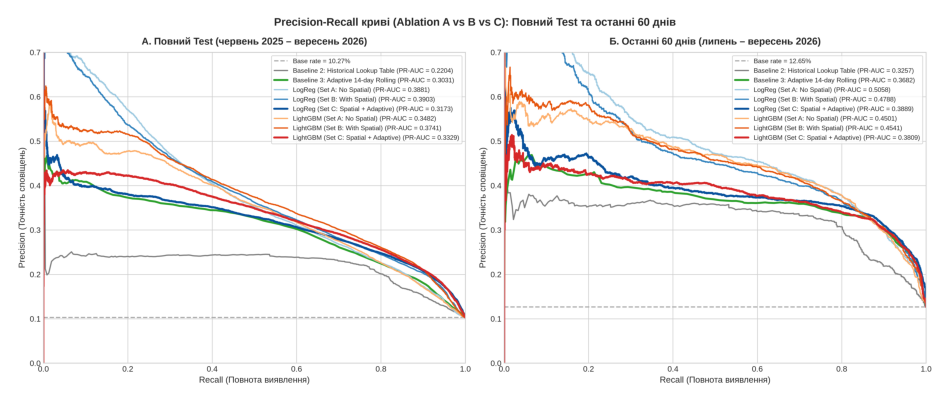

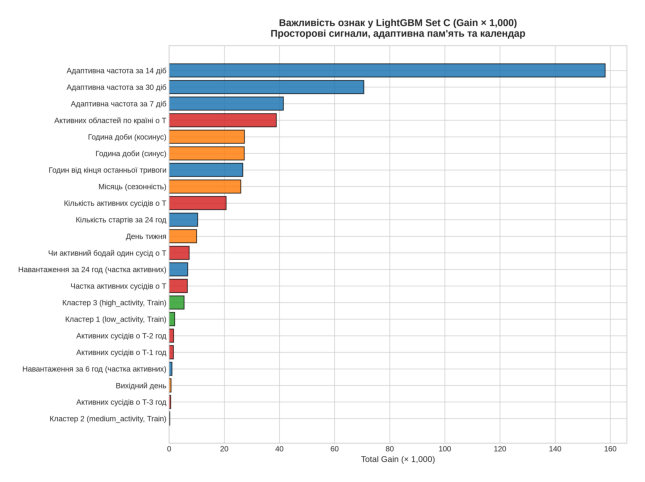

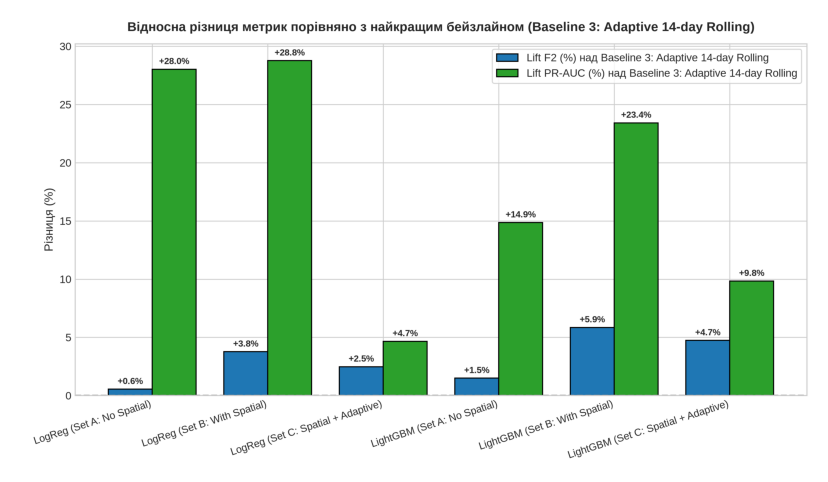

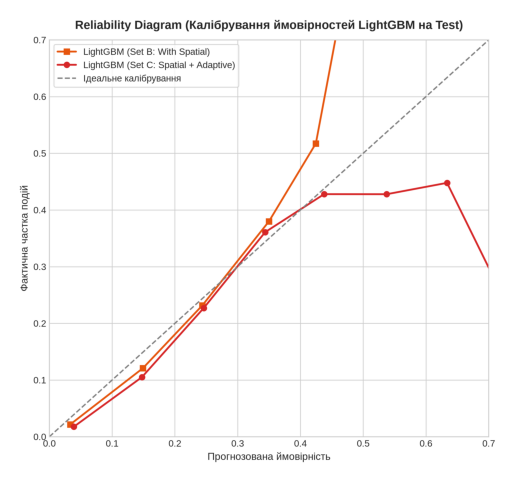

In [6]:
display(imp_df)
for fig_name in ["10_test_pr_curves_comparison.png", "11_feature_importance_lightgbm.png", "12_lift_over_baselines.png", "13_calibration_reliability_diagram.png"]:
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.imshow(mpimg.imread(reports_dir / "figures" / fig_name))
    ax.axis("off")
    plt.show()